In [37]:
import pandas as pd
import geopandas as gpd
import json
from shapely.geometry import Point

# 1. Load the JSON data
with open("../../03_data_raw/exploration_inputs/IEA_2025 (1).json", 'r', encoding='utf-8') as f:
    data = json.load(f)

df = pd.DataFrame(data)

# 2. Filter for only Car Assembly plants (optional: you can remove this to count ALL facilities)
df_assembly = df[df["type"].isin(["Assembly - car", "In-house component", "Steel plant"])].copy()
# 3. Convert the lat/lon columns into proper geometry points
# Note: GPS coordinates are usually listed as (Longitude, Latitude) in geometry
geometry = [Point(xy) for xy in zip(df_assembly['lon'].astype(float), df_assembly['lat'].astype(float))]

# Create a GeoDataFrame
gdf_plants = gpd.GeoDataFrame(df_assembly, geometry=geometry)

# Set the Coordinate Reference System (CRS) to standard GPS (WGS84 / EPSG:4326)
gdf_plants.set_crs(epsg=4326, inplace=True)

# 4. Load a NUTS-2 map of Europe (You can download this from Eurostat's GISCO database)
# Make sure to replace this with your actual downloaded map file path
nuts_map = gpd.read_file("/Users/majdshamashan/Downloads/NUTS_RG_20M_2024_4326.geojson")

# 5. Perform the Spatial Join
# This matches each plant's GPS point to the polygon of the region it falls inside
plants_with_regions = gpd.sjoin(gdf_plants, nuts_map, how="inner", predicate="intersects")

# 6. Group and Count the plants per Country and Region
# NUTS shapefiles usually have 'CNTR_CODE' for country and 'NUTS_NAME' for the region
assembly_regional_counts = (plants_with_regions
                   .groupby(['CNTR_CODE', 'NUTS_NAME'])
                   .size()
                   .reset_index(name='Assembly_Plant_Count'))

# Sort the results so the regions with the most plants are at the top
assembly_regional_counts = regional_counts.sort_values(by=['Assembly_Plant_Count'], ascending=False)

print("--- Top European Regions by Number of Assembly Car Plants ---")
print(assembly_regional_counts.head(25).to_string(index=False))

# Save the final table
# regional_counts.to_csv("plants_per_region.csv", index=False)

--- Top European Regions by Number of Assembly Car Plants ---
CNTR_CODE          NUTS_NAME  Assembly_Plant_Count
       DE        Deutschland                    31
       FR             France                    18
       SK          Slovensko                    16
       CZ              Česko                    14
       ES             España                    11
       IT             Italia                    10
       FR               Nord                     8
       FR Nord-Pas de Calais                     8
       DE             Bayern                     8
       FR    Hauts-de-France                     8
       DE  Baden-Württemberg                     8
       HU       Magyarország                     7
       PL             Polska                     6
       DE          Stuttgart                     6
       DE      Niedersachsen                     6
       FR          Grand Est                     4
       HU           Dunántúl                     4
       SK  Bratislav

In [2]:
!pip install geopandas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 342.5/342.5 kB 7.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 30.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 45.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 43.1 MB/s eta 0:00:0000:01


In [27]:
assembly_regional_counts

,CNTR_CODE,NUTS_NAME,Assembly_Plant_Count
26,DE,Deutschland,31
86,FR,France,18
174,SK,Slovensko,16
17,CZ,Česko,14
70,ES,España,11
...,...,...,...
148,PT,Médio Tejo,1
149,PT,Oeste e Vale do Tejo,1
164,SE,Sverige,1
143,PL,Tyski,1


In [38]:
assembly_regional_counts.to_excel('../../03_data_raw/exploration_inputs/assembly_regional_counts.xlsx', index=False)

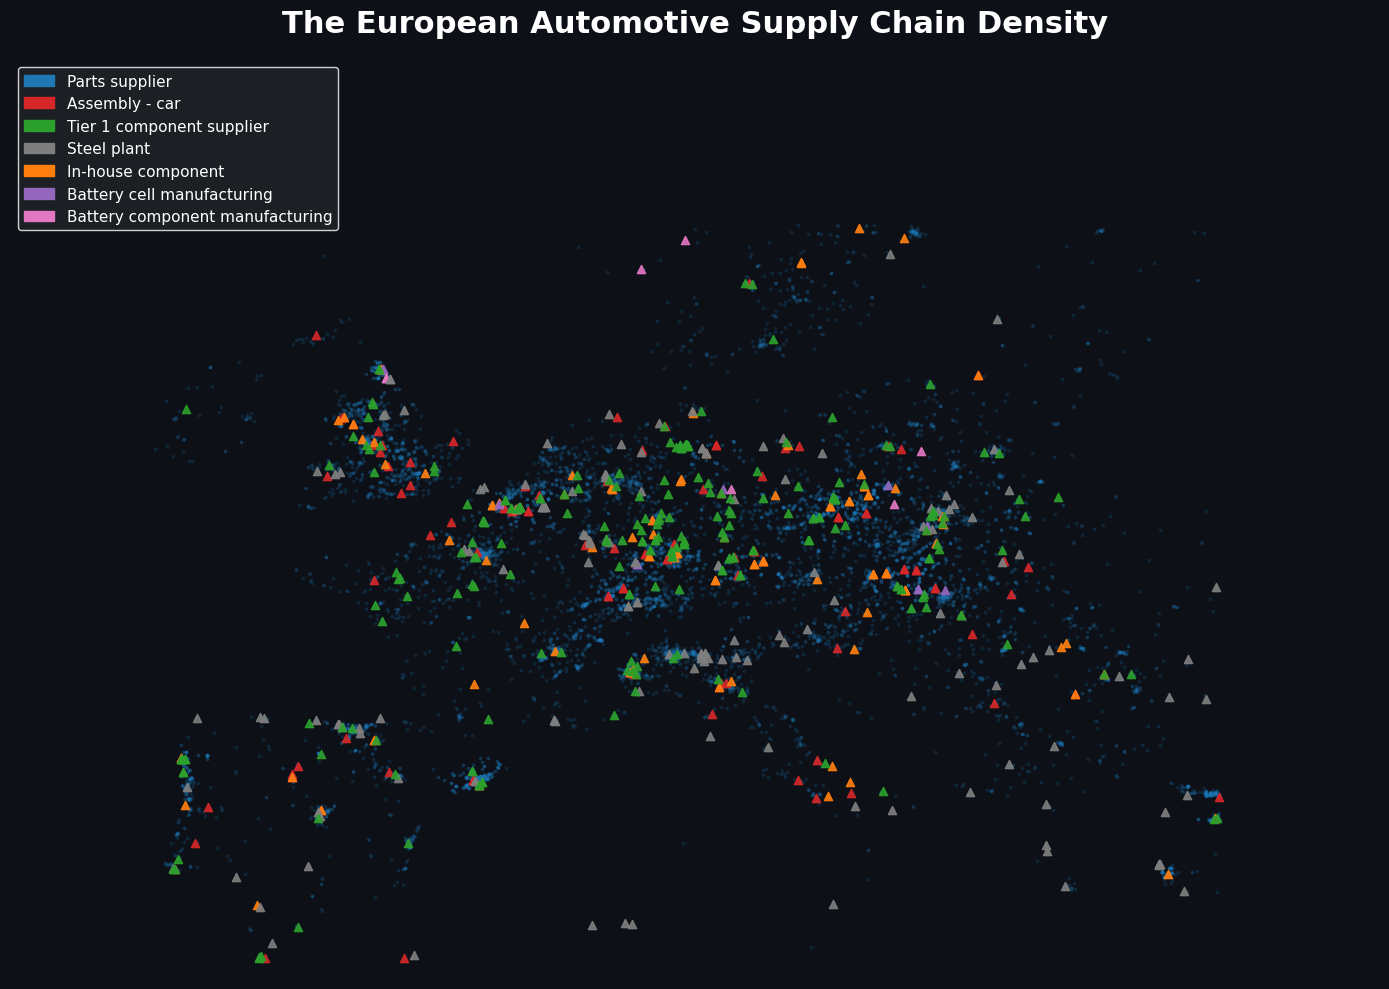

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json

# 1. Load the data
with open("../../03_data_raw/exploration_inputs/IEA_2025 (1).json", 'r', encoding='utf-8') as f:
    data = json.load(f)
df = pd.DataFrame(data)

# 2. Convert coordinates from strings to numeric floats
df['lon'] = pd.to_numeric(df['lon'])
df['lat'] = pd.to_numeric(df['lat'])

# 3. Filter for European clusters (EU_full and Europe_mega)
df_eu = df[df['Cluster_na'].isin(['EU_full', 'Europe_mega'])].copy()

# 4. Define a color map for different facility types
colors = {
    'Parts supplier': '#1f77b4',              # Blue
    'Assembly - car': '#d62728',              # Red
    'Tier 1 component supplier': '#2ca02c',   # Green
    'Steel plant': '#7f7f7f',                 # Grey
    'In-house component': '#ff7f0e',          # Orange
    'Battery cell manufacturing': '#9467bd',  # Purple
    'Battery component manufacturing': '#e377c2' # Pink
}

# 5. Split the data into background (parts) and foreground (everything else)
# We do this so the thousands of parts suppliers don't cover up the main assembly plants
parts = df_eu[df_eu['type'] == 'Parts supplier']
others = df_eu[df_eu['type'] != 'Parts supplier']

# 6. Set up the plot and styling
fig, ax = plt.subplots(figsize=(14, 10))

# Set background color to dark for a cool data-viz look (optional)
ax.set_facecolor('#0d1117')
fig.patch.set_facecolor('#0d1117')

# 7. Plot the Parts Suppliers (Dense background)
# 's' is marker size, 'alpha' is transparency
ax.scatter(parts['lon'], parts['lat'], s=3, c='#1f77b4', alpha=0.15, label='Parts supplier')

# 8. Plot the other major facilities on top
for facility_type in others['type'].unique():
    subset = others[others['type'] == facility_type]
    ax.scatter(subset['lon'], subset['lat'], s=35, c=colors[facility_type], alpha=0.9, marker='^', label=facility_type)

# 9. Set map limits to focus precisely on Europe (Longitudes -15 to 35, Latitudes 35 to 65)
ax.set_xlim(-15, 35)
ax.set_ylim(35, 65)

# 10. Final Styling
ax.set_title("The European Automotive Supply Chain Density", fontsize=22, fontweight='bold', color='white', pad=20)
ax.axis('off') # Hide the axis lines and numbers

# 11. Custom Legend
legend_handles = [mpatches.Patch(color=color, label=label) for label, color in colors.items()]
legend = ax.legend(handles=legend_handles, loc='upper left', fontsize=11, frameon=True, facecolor='#212529', edgecolor='white', labelcolor='white')

# 12. Save and display
plt.tight_layout()
plt.savefig('my_europe_supply_chain_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd
import geopandas as gpd
import json
from shapely.geometry import Point

# ==========================================
# 1. DEFINE CUSTOM REGION GROUPINGS
# ==========================================
france_regions = {
    "Île-de-France": ["Île-de-France"],
    "Centre-Val de Loire": ["Centre-Val de Loire"],
    "Bourgogne-Franche-Comté": ["Bourgogne", "Franche-Comté"],
    "Normandie": ["Basse-Normandie", "Haute-Normandie"],
    "Hauts-de-France": ["Nord-Pas-de-Calais", "Picardie"],
    "Grand Est": ["Alsace", "Champagne-Ardenne", "Lorraine"],
    "Pays de la Loire": ["Pays de la Loire"],
    "Bretagne": ["Bretagne"],
    "Nouvelle-Aquitaine": ["Aquitaine", "Limousin", "Poitou-Charentes"],
    "Occitanie": ["Languedoc-Roussillon", "Midi-Pyrénées"],
    "Auvergne-Rhône-Alpes": ["Auvergne", "Rhône-Alpes"],
    "Provence-Alpes-Côte d’Azur": ["Provence-Alpes-Côte d’Azur"],
    "Corse": ["Corse"]
}

germany_regions = {
    "Baden-Württemberg": ["Stuttgart", "Karlsruhe", "Freiburg", "Tübingen"],
    "Bayern": ["Oberbayern", "Niederbayern", "Oberpfalz", "Oberfranken", "Mittelfranken", "Unterfranken", "Schwaben"],
    "Berlin": ["Berlin"],
    "Brandenburg": ["Brandenburg - Nordost", "Brandenburg - Südwest"],
    "Bremen": ["Bremen"],
    "Hamburg": ["Hamburg"],
    "Hessen": ["Darmstadt", "Gießen", "Kassel"],
    "Mecklenburg-Vorpommern": ["Mecklenburg-Vorpommern"],
    "Niedersachsen": ["Braunschweig", "Hannover", "Lüneburg", "Weser-Ems"],
    "Nordrhein-Westfalen": ["Düsseldorf", "Köln", "Münster", "Detmold", "Arnsberg"],
    "Rheinland-Pfalz": ["Koblenz", "Trier", "Rheinhessen-Pfalz"],
    "Saarland": ["Saarland"],
    "Sachsen": ["Chemnitz", "Dresden", "Leipzig"],
    "Sachsen-Anhalt": ["Sachsen-Anhalt"],
    "Schleswig-Holstein": ["Schleswig-Holstein"],
    "Thüringen": ["Thüringen"]
}

# Combine into one master dictionary for the mapping function
macro_mapping = {**france_regions, **germany_regions}

def map_to_macro_region(region_name):
    """
    Checks if a NUTS-2 region name contains any of the sub-region 
    keywords defined in our custom dictionaries.
    """
    if pd.isna(region_name): 
        return None
    
    # Clean the input string (lowercase, replace hyphens with spaces for fuzzy matching)
    clean_name = str(region_name).lower().replace('-', ' ')
    
    for macro, subs in macro_mapping.items():
        for sub in subs:
            clean_sub = sub.lower().replace('-', ' ')
            if clean_sub in clean_name:
                return macro
                
    # If no match is found, return the original Eurostat NUTS-2 name
    return region_name 


# ==========================================
# 2. LOAD AND PREPARE THE DATA
# ==========================================
with open("../../03_data_raw/exploration_inputs/IEA_2025 (1).json", 'r', encoding='utf-8') as f:
    data = json.load(f)

df = pd.DataFrame(data)

# Convert coordinates from strings to numeric floats
df['lon'] = pd.to_numeric(df['lon'])
df['lat'] = pd.to_numeric(df['lat'])


# ==========================================
# 3. PERFORM SPATIAL JOIN
# ==========================================
print("Converting coordinates to spatial points...")
# Note: GPS coordinates are passed as (Longitude, Latitude) to shapely
geometry = [Point(xy) for xy in zip(df['lon'], df['lat'])]

# Create a GeoDataFrame using the full dataset
gdf_plants = gpd.GeoDataFrame(df, geometry=geometry)

# Set the Coordinate Reference System (CRS) to standard GPS (WGS84 / EPSG:4326)
gdf_plants.set_crs(epsg=4326, inplace=True)

print("Loading Eurostat NUTS-2 map...")
# MAKE SURE THIS FILE EXISTS IN YOUR DIRECTORY!
try:
    nuts_map = gpd.read_file("/Users/majdshamashan/Downloads/NUTS_RG_20M_2024_4326.geojson")
except FileNotFoundError:
    print("\nERROR: Map file not found! Please download the NUTS-2 geojson from Eurostat.")
    exit()

print("Performing spatial join (dropping pins on the map)...")
# This matches each plant's GPS point to the NUTS-2 polygon it falls inside
plants_with_regions = gpd.sjoin(gdf_plants, nuts_map, how="inner", predicate="intersects")


# ==========================================
# 4. APPLY CUSTOM RENAMING & AGGREGATE
# ==========================================
print("Applying custom French/German region groupings...")
# The spatial join added a column called 'NUTS_NAME' from the shapefile
plants_with_regions['Custom_Region'] = plants_with_regions['NUTS_NAME'].apply(map_to_macro_region)

# Group and Count ALL facilities per Country and our Custom Region
print("Calculating final totals...")
final_counts = (plants_with_regions
                   .groupby(['CNTR_CODE', 'Custom_Region'])
                   .size()
                   .reset_index(name='Total_Facilities_Count'))

# Sort the results so the regions with the most facilities are at the top
final_counts = final_counts.sort_values(by=['Total_Facilities_Count'], ascending=False)

print("\n--- TOP EUROPEAN REGIONS BY TOTAL AUTOMOTIVE FACILITIES ---")
print(final_counts.head(25).to_string(index=False))

# Save the final table to Excel/CSV
final_counts.to_excel("/Users/majdshamashan/Downloads/grouped_facilities_per_region.xlsx", index=False)


Converting coordinates to spatial points...
Loading Eurostat NUTS-2 map...
Performing spatial join (dropping pins on the map)...
Applying custom French/German region groupings...
Calculating final totals...

--- TOP EUROPEAN REGIONS BY TOTAL AUTOMOTIVE FACILITIES ---
CNTR_CODE           Custom_Region  Total_Facilities_Count
       CZ                   Česko                    1926
       FR                  France                    1556
       DE             Deutschland                    1486
       ES                  España                    1344
       PL                  Polska                     972
       DE       Baden-Württemberg                     938
       IT                  Italia                     923
       SK               Slovensko                     788
       DE                  Bayern                     692
       ES                    Este                     663
       ES                Cataluña                     594
       IT              Nord-Ovest   

In [24]:
final_counts.to_excel("/Users/majdshamashan/Downloads/grouped_facilities_per_region.xlsx", index=False)


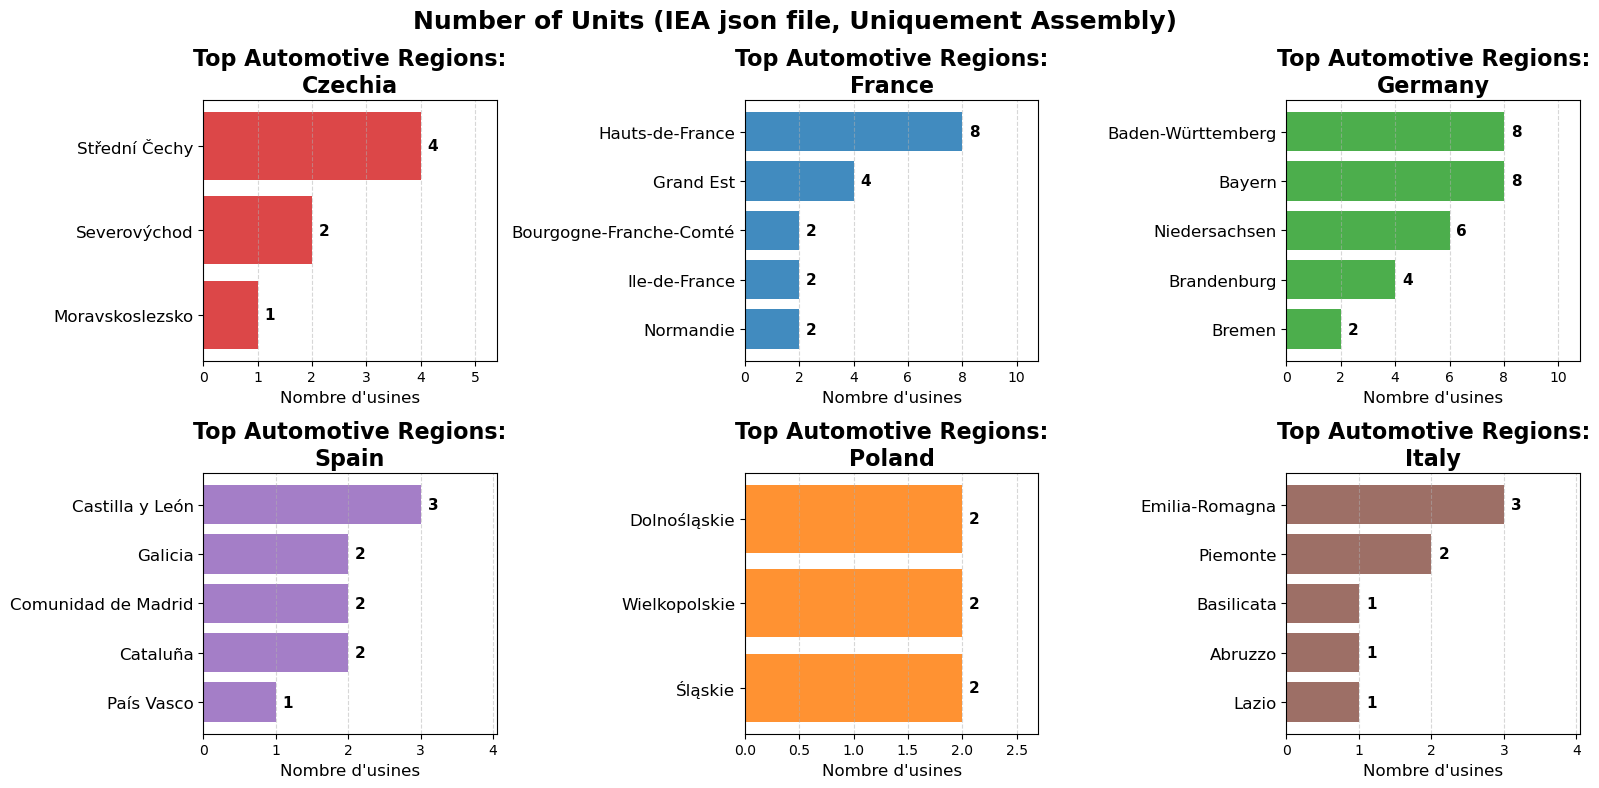

In [58]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
# Make sure "regional_counts.xlsx" is in the same directory as this script
df = pd.read_excel('../../03_data_raw/exploration_inputs/assembly_regional_counts.xlsx')

# 2. Define the Top 6 Countries to plot
countries = ['CZ', 'FR', 'DE', 'ES', 'PL', 'IT']
country_names = {
    'CZ': 'Czechia', 
    'FR': 'France', 
    'DE': 'Germany', 
    'ES': 'Spain', 
    'PL': 'Poland', 
    'IT': 'Italy'
}

# 3. Define valid macro-regions to prevent double-counting overlapping sub-regions
# This strictly filters France to its 13 regions and Germany to its 16 states
# Here we can only choose the large region names since the regional_counts dataset counts the number of plants within each small region constituting the large region. 
valid_regions = {
    'DE': [
        "Baden-Württemberg", "Bayern", "Berlin", "Brandenburg", "Bremen", 
        "Hamburg", "Hessen", "Mecklenburg-Vorpommern", "Niedersachsen", 
        "Nordrhein-Westfalen", "Rheinland-Pfalz", "Saarland", "Sachsen", 
        "Sachsen-Anhalt", "Schleswig-Holstein", "Thüringen"
    ],
    'FR': [
        "Ile-de-France", "Centre — Val de Loire", "Bourgogne-Franche-Comté",
        "Normandie", "Hauts-de-France", "Grand Est", "Pays de la Loire",
        "Bretagne", "Nouvelle-Aquitaine", "Occitanie", "Auvergne-Rhône-Alpes",
        "Provence-Alpes-Côte d’Azur", "Corse"
    ],
    'CZ': ["Praha", "Střední Čechy", "Jihozápad", "Severozápad", "Severovýchod", "Jihovýchod", "Střední Morava", "Moravskoslezsko"],
    'PL': ["Małopolskie", "Śląskie", "Wielkopolskie", "Zachodniopomorskie", "Lubuskie", "Dolnośląskie", "Opolskie", "Kujawsko-Pomorskie", "Pomorskie", "Warmińsko-Mazurskie", "Podlaskie", "Warszawski stołeczny", "Mazowieckie regionalne", "Świętokrzyskie", "Lubelskie", "Podkarpackie", "Łódzkie"],
    'ES': ["Galicia", "Principado de Asturias", "Cantabria", "País Vasco", "Comunidad Foral de Navarra", "La Rioja", "Aragón", "Comunidad de Madrid", "Castilla y León", "Castilla-La Mancha", "Extremadura", "Cataluña", "Comunitat Valenciana", "Illes Balears", "Andalucía", "Región de Murcia", "Canarias"],
    'IT': ["Piemonte", "Valle d'Aosta/Vallée d'Aoste", "Liguria", "Lombardia", "Abruzzo", "Molise", "Campania", "Puglia", "Basilicata", "Calabria", "Sicilia", "Sardegna", "Provincia Autonoma di Bolzano/Bozen", "Provincia Autonoma di Trento", "Veneto", "Friuli-Venezia Giulia", "Emilia-Romagna", "Toscana", "Umbria", "Marche", "Lazio"]
}

# 4. Set up the plotting grid (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Number of Units (IEA json file, Uniquement Assembly)', fontsize=18, fontweight='bold')

axes = axes.flatten() # Flatten the 2D array of axes for easier looping

# Assign a specific color to each country's chart
colors = ['#d62728', '#1f77b4', '#2ca02c', '#9467bd', '#ff7f0e', '#8c564b']

# 5. Loop through the countries and generate each subplot
for i, cc in enumerate(countries):
    ax = axes[i]
    
    # Filter the dataframe for this specific country and its valid regions
    subset = df[(df['CNTR_CODE'] == cc) & (df['NUTS_NAME'].isin(valid_regions[cc]))]
    
    # Get the Top 5 regions by plant count
    top5 = subset.sort_values(by='Assembly_Plant_Count', ascending=False).head(5)
    
    # Sort ascending so the largest bar appears at the top of the horizontal chart
    top5 = top5.sort_values(by='Assembly_Plant_Count', ascending=True)
    
    # Create the horizontal bar chart
    bars = ax.barh(top5['NUTS_NAME'], top5['Assembly_Plant_Count'], color=colors[i], alpha=0.85)
    
    # Add Titles and Labels
    ax.set_title(f'Top Automotive Regions:\n{country_names[cc]}', fontsize=16, fontweight='bold')
    ax.set_xlabel("Nombre d'usines", fontsize=12)
    
    # Add exact numeric data labels to the end of each bar
    for bar in bars:
        width = bar.get_width()
        ax.annotate(f'{int(width):,}',
                    xy=(width, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0), # 5 points of padding to the right
                    textcoords="offset points",
                    ha='left', va='center', fontsize=11, fontweight='bold')
    
    # Extend the x-axis limit by 35% so the data labels don't get cut off
    max_val = top5['Assembly_Plant_Count'].max()
    ax.set_xlim(0, max_val * 1.35)
    
    # Apply styling (font sizes and a dashed grid for readability)
    ax.tick_params(axis='y', labelsize=12)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

# 6. Finalize layout and save the image
plt.tight_layout()
#plt.savefig('top6_countries_top5_regions.png', dpi=150, bbox_inches='tight')
#print("Chart generated successfully and saved as 'top6_countries_top5_regions.png'")
plt.show()

In [53]:


final_df.to_excel('../../03_data_raw/exploration_inputs/palnts_per_region.xlsx', index=False)


In [52]:
# 1. Initialize an empty list to store the filtered chunks
filtered_dfs = []

# 2. Loop through the countries to filter the data
for cc in countries:
    # Filter for the country and its specific valid regions
    subset = df[(df['CNTR_CODE'] == cc) & (df['NUTS_NAME'].isin(valid_regions[cc]))]
    
    # Append the subset to our list
    filtered_dfs.append(subset)

# 3. Concatenate all pieces into one final DataFrame
final_df = pd.concat(filtered_dfs, ignore_index=True)

# 4. Optional: Clean up or Sort (e.g., see the top regions across all 6 countries)
final_df = final_df.sort_values(by=['CNTR_CODE', 'Assembly_Plant_Count'], ascending=[True, False])

# Display the result
print(final_df.head())

   CNTR_CODE          NUTS_NAME  Assembly_Plant_Count
0         CZ      Střední Čechy                     4
1         CZ       Severovýchod                     2
2         CZ    Moravskoslezsko                     1
9         DE             Bayern                     8
10        DE  Baden-Württemberg                     8
